# Machine Learning Analysis: Fit Score & Candidate Level
This notebook explores how the `Expected Fit Score` and `Candidate Level` are calculated by building machine learning models.
We will filter out `Unusual/Surprise` candidates to focus on the core scoring logic.

## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier

import os
os.makedirs('charts', exist_ok=True)

# Load data
df = pd.read_csv('../DATA/Datathon Database - CV Database.csv')
print(f"Original shape: {df.shape}")

# Filter out Unusual/Surprise
df = df[df['Candidate Level'] != 'Unusual/Surprise'].copy()
print(f"Filtered shape (excluding Unusual/Surprise): {df.shape}")


Original shape: (175, 18)
Filtered shape (excluding Unusual/Surprise): (150, 18)


## 2. Feature Engineering
We extract numeric counts from lists (like Skills and Tools) and one-hot encode categorical variables.

In [2]:
# Feature Engineering
def count_items(text):
    if pd.isna(text): return 0
    return len([x for x in str(text).split(',') if x.strip() and x.strip().lower() != 'basic communication'])

df['Num_Skills'] = df['Core Skills'].apply(count_items)
df['Num_Tools'] = df['Tools'].apply(count_items)
df['Experience_Summary_Length'] = df['Experience Summary'].fillna('').apply(len)

# Categorical features
cat_cols = ['Role', 'Education', 'Certification']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=False)

# Target Variables
X = df_encoded[['Years Experience', 'Num_Skills', 'Num_Tools', 'Experience_Summary_Length'] + 
               [col for col in df_encoded.columns if col.startswith(('Role_', 'Education_', 'Certification_'))]]

# Fill missing values if any
X = X.fillna(0)

y_score = df_encoded['Expected Fit Score']
y_level = df_encoded['Candidate Level']

X.head()

,Years Experience,Num_Skills,Num_Tools,Experience_Summary_Length,Role_Backend Developer,Role_Data Analyst,Role_Digital Marketing Specialist,Role_Financial Analyst,Role_Project Manager,Education_BA Media,...,Certification_CFA Level I,Certification_Excel certificate,Certification_Google Analytics Certification,Certification_Google certificate,Certification_Introductory certification,Certification_Microsoft PL-300,Certification_Online course,Certification_PMP,Certification_Scrum Master,Certification_University project certificate
0,9,8,3,133,False,False,False,False,True,False,...,False,False,False,False,False,False,False,True,False,False
1,6,8,3,142,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,False,False
2,8,8,3,146,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,False,False
3,6,8,3,142,False,False,False,False,True,False,...,False,False,False,False,False,False,False,False,True,False
4,6,8,3,146,False,False,False,False,True,False,...,False,False,True,False,False,False,False,False,False,False


## 3. Predicting Expected Fit Score (Regression)
We will test three models: Linear Regression, Random Forest, and Gradient Boosting.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y_score, test_size=0.2, random_state=42)

reg_models = {
    'Linear Regression': LinearRegression(),
    'Random Forest Regressor': RandomForestRegressor(random_state=42, n_estimators=100),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42)
}

best_reg_model = None
best_r2 = -float('inf')

for name, model in reg_models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    print(f"{name}:")
    print(f"  RMSE: {rmse:.2f}")
    print(f"  R2:   {r2:.3f}")
    print()
    if r2 > best_r2:
        best_r2 = r2
        best_reg_model = (name, model)

print(f"Best Model for Fit Score: {best_reg_model[0]} with R2 = {best_r2:.3f}")


Linear Regression:
  RMSE: 6.95
  R2:   0.890

Random Forest Regressor:
  RMSE: 6.27
  R2:   0.911

Gradient Boosting Regressor:
  RMSE: 7.43
  R2:   0.875

Best Model for Fit Score: Random Forest Regressor with R2 = 0.911


### Feature Importance for Fit Score

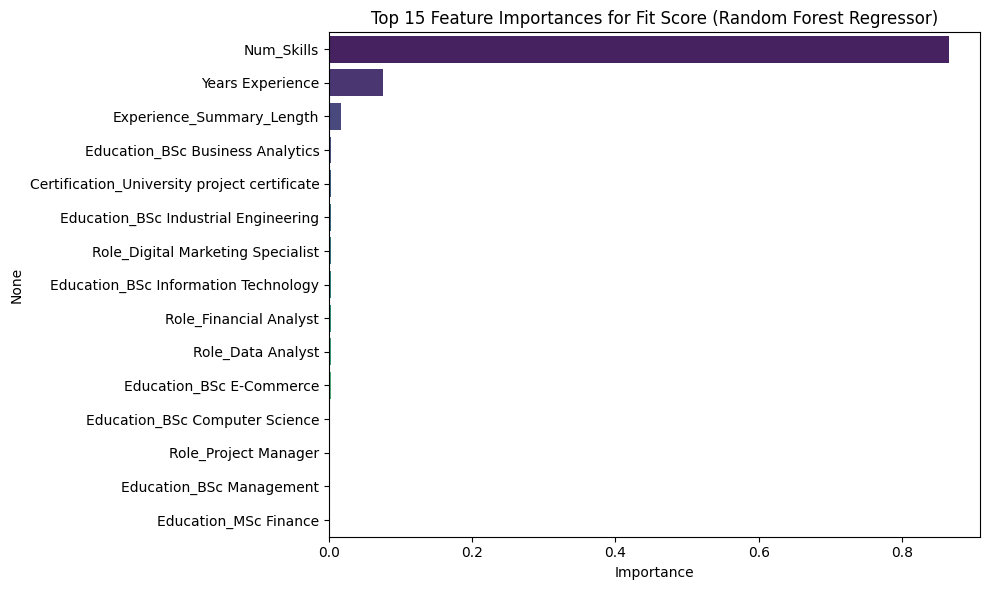

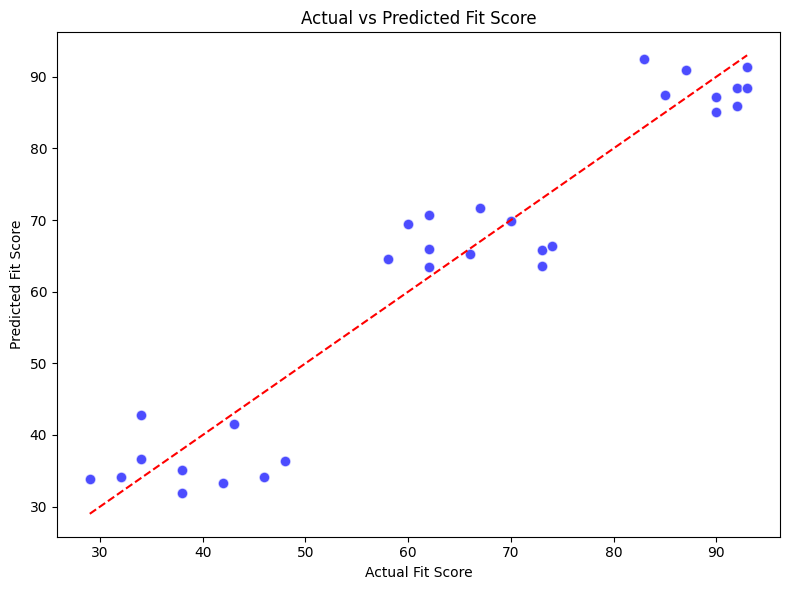

In [4]:
model_reg = best_reg_model[1]

# Feature Importance
if hasattr(model_reg, 'feature_importances_'):
    importances = model_reg.feature_importances_
elif hasattr(model_reg, 'coef_'):
    importances = np.abs(model_reg.coef_)

feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp.values, y=feat_imp.index, palette='viridis')
plt.title(f'Top 15 Feature Importances for Fit Score ({best_reg_model[0]})')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('charts/ml_fitscore_feature_importance.png', dpi=150)
plt.show()

# Actual vs Predicted
preds = model_reg.predict(X_test)
plt.figure(figsize=(8, 6))
plt.scatter(y_test, preds, alpha=0.7, color='blue', edgecolor='white', s=60)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual Fit Score')
plt.ylabel('Predicted Fit Score')
plt.title('Actual vs Predicted Fit Score')
plt.tight_layout()
plt.savefig('charts/ml_fitscore_actual_vs_pred.png', dpi=150)
plt.show()


## 4. Predicting Candidate Level (Classification)
We test Logistic Regression, Random Forest Classifier, and Gradient Boosting Classifier.

In [5]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X, y_level, test_size=0.2, random_state=42, stratify=y_level)

clf_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest Classifier': RandomForestClassifier(random_state=42, n_estimators=100),
    'Gradient Boosting Classifier': GradientBoostingClassifier(random_state=42)
}

best_clf_model = None
best_acc = -float('inf')

for name, model in clf_models.items():
    model.fit(X_train_c, y_train_c)
    preds = model.predict(X_test_c)
    acc = accuracy_score(y_test_c, preds)
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.3f}")
    if acc > best_acc:
        best_acc = acc
        best_clf_model = (name, model)

print(f"Best Model for Candidate Level: {best_clf_model[0]} with Accuracy = {best_acc:.3f}")

# Full classification report for best model
print()
print("Classification Report (Best Model):")
preds = best_clf_model[1].predict(X_test_c)
print(classification_report(y_test_c, preds))


=== Logistic Regression ===
Accuracy: 1.000
=== Random Forest Classifier ===
Accuracy: 1.000
=== Gradient Boosting Classifier ===
Accuracy: 1.000
Best Model for Candidate Level: Logistic Regression with Accuracy = 1.000

Classification Report (Best Model):
              precision    recall  f1-score   support

     Average       1.00      1.00      1.00        10
      Strong       1.00      1.00      1.00        10
        Weak       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



### Feature Importance for Candidate Level

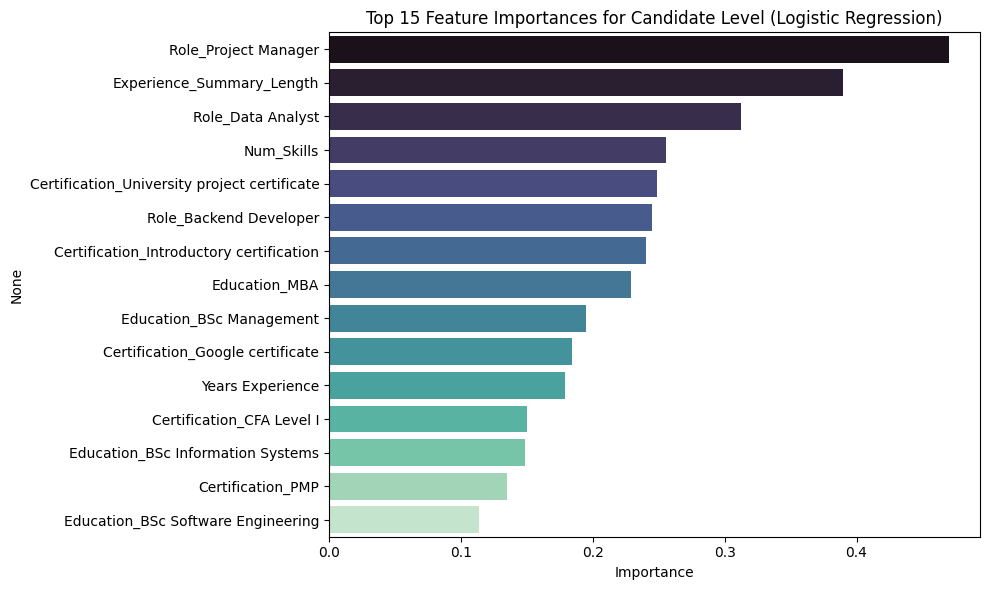

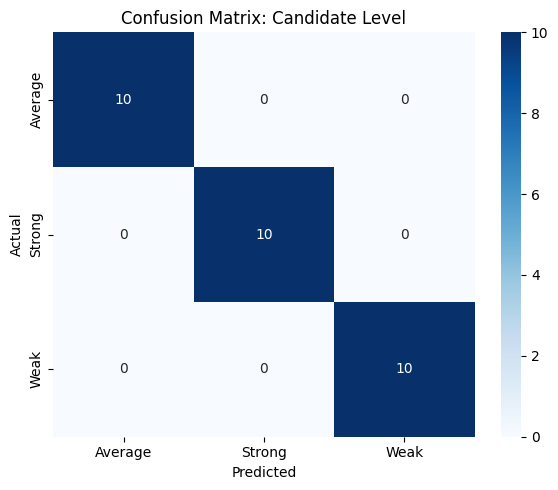

In [6]:
model_clf = best_clf_model[1]

# Feature Importance
if hasattr(model_clf, 'feature_importances_'):
    importances_c = model_clf.feature_importances_
elif hasattr(model_clf, 'coef_'):
    importances_c = np.abs(model_clf.coef_[0])

feat_imp_c = pd.Series(importances_c, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=feat_imp_c.values, y=feat_imp_c.index, palette='mako')
plt.title(f'Top 15 Feature Importances for Candidate Level ({best_clf_model[0]})')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('charts/ml_candidate_level_feature_importance.png', dpi=150)
plt.show()

# Confusion Matrix
cm = confusion_matrix(y_test_c, preds, labels=best_clf_model[1].classes_)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=best_clf_model[1].classes_, yticklabels=best_clf_model[1].classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Candidate Level')
plt.tight_layout()
plt.savefig('charts/ml_candidate_level_confusion_matrix.png', dpi=150)
plt.show()
